In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
import open3d as o3d

## Calibration and rectification

In [2]:
test = globals().update(np.load("calibration_values.npz", allow_pickle=True))

with np.load("calibration_values.npz", allow_pickle=True) as test:
    table = pd.DataFrame([
        {
            "Parameter": key,
            "Shape": test[key].shape,
            "Data type": test[key].dtype,
            "Value": np.array2string(
                test[key],
                precision=4,
                suppress_small=True
            )
        }
        for key in test.files
    ])

display(table.style.hide(axis="index"))

Parameter,Shape,Data type,Value
ret_R,(),float64,0.9295
mtx_R,"(3, 3)",float64,[[682.7995 0. 629.6059] [ 0. 672.8049 389.1799] [ 0. 0. 1. ]]
dist_R,"(1, 5)",float64,[[-0.1157 0.2873 -0.0004 -0.006 -0.2227]]
rvecs_R,"(25, 3, 1)",float64,[[[ 0.0414] [ 0.1066] [ 0.571 ]] [[ 0.1514] [ 0.5924] [ 0.5083]] [[ 0.1644] [ 0.6958] [ 0.4741]] [[-0.143 ] [-0.4114] [ 0.5799]] [[-0.0556] [-0.0852] [ 0.5723]] [[-0.1406] [-0.3012] [ 0.5843]] [[-0.0531] [-0.6706] [ 0.6769]] [[-0.2094] [-0.5584] [ 0.7259]] [[-0.0295] [ 0.5659] [ 0.5032]] [[ 0.0564] [ 0.8138] [ 0.3875]] [[ 0.2017] [ 0.4879] [ 0.5274]] [[ 0.3879] [ 0.4482] [ 0.612 ]] [[-0.1214] [-0.2779] [ 0.6175]] [[ 0.1183] [-0.3902] [ 0.5879]] [[ 0.1527] [-0.6412] [ 0.5648]] [[ 0.1329] [-0.7647] [ 0.5686]] [[-0.0911] [-0.1406] [ 0.6108]] [[-0.1152] [ 0.3235] [ 0.3384]] [[-0.1333] [-0.0597] [ 0.3712]] [[-0.1583] [ 0.1902] [ 0.364 ]] [[-0.0226] [ 0.7912] [ 0.2217]] [[-1.2528] [-0.252 ] [-2.489 ]] [[-0.437 ] [ 0.4851] [-0.3235]] [[ 0.3958] [ 0.3745] [ 0.0469]] [[-0.3601] [ 0.0862] [ 0.0008]]]
tvecs_R,"(25, 3, 1)",float64,[[[ 6.221 ] [ -7.6896] [ 41.2328]] [[ 19.8783] [ -8.3583] [ 32.8028]] [[ 25.197 ] [ -6.7949] [ 51.6047]] [[ 3.2047] [ -5.7557] [ 62.9715]] [[-13.117 ] [ -6.7923] [ 49.4558]] [[-19.6792] [ -8.3237] [ 29.5319]] [[-13.9218] [ -5.2007] [ 27.5693]] [[-10.4884] [ -1.909 ] [ 20.5952]] [[ -0.3174] [ -3.9328] [ 14.2158]] [[ 7.6274] [ -3.6926] [ 16.4498]] [[ 6.3463] [ -7.0935] [ 15.4867]] [[ -4.3263] [-12.86 ] [ 27.2192]] [[ -5.0695] [ -0.3148] [ 28.7465]] [[ -6.8112] [ -7.991 ] [ 27.2596]] [[-12.4955] [ -9.7312] [ 24.152 ]] [[-15.0303] [ -9.5976] [ 22.5874]] [[ -1.5362] [ -0.4057] [ 29.2948]] [[ 4.0487] [ 7.3319] [ 59.5095]] [[ 4.0729] [ 7.3738] [ 59.6358]] [[ -7.5675] [ 7.0686] [ 59.7978]] [[ 25.2003] [ 6.0814] [ 54.4673]] [[ 37.2965] [ 10.9088] [ 49.1754]] [[ -6.2872] [ -1.1537] [ 24.1018]] [[ -5.7566] [ -3.5334] [ 20.5616]] [[ 0.2751] [ 1.2643] [ 28.2011]]]
ret_L,(),float64,1.2929
mtx_L,"(3, 3)",float64,[[648.4507 0. 671.4224] [ 0. 642.1726 421.1284] [ 0. 0. 1. ]]
dist_L,"(1, 5)",float64,[[-0.0794 0.1438 0.0165 0.0026 -0.0944]]
rvecs_L,"(25, 3, 1)",float64,[[[ 0.0687] [ 0.024 ] [ 0.5644]] [[ 0.2363] [ 0.5547] [ 0.5031]] [[ 0.2469] [ 0.6851] [ 0.4821]] [[-0.0742] [-0.455 ] [ 0.5571]] [[ 0.1321] [-0.4529] [ 0.5746]] [[-0.0724] [-0.3746] [ 0.5927]] [[-0.0159] [-0.6347] [ 0.6624]] [[-0.2233] [-0.5717] [ 0.6949]] [[ 0.0287] [ 0.5242] [ 0.5222]] [[ 0.1357] [ 0.7806] [ 0.3919]] [[ 0.2859] [ 0.4792] [ 0.5288]] [[ 0.4179] [ 0.3829] [ 0.6334]] [[-0.0203] [ 0.5253] [ 0.5508]] [[-0.0585] [-0.2387] [ 0.6074]] [[ 0.203 ] [-0.4045] [ 0.585 ]] [[ 0.2367] [-0.6937] [ 0.5581]] [[ 0.19 ] [-0.7628] [ 0.564 ]] [[-0.0317] [-0.1021] [ 0.6024]] [[-0.0828] [-0.3061] [ 0.4015]] [[ 0.038 ] [ 0.7637] [ 0.2348]] [[ 0.2111] [ 0.3325] [ 0.255 ]] [[-0.3485] [ 0.451 ] [-0.3053]] [[ 0.4745] [ 0.3433] [ 0.0776]] [[-0.2742] [ 0.0681] [-0.0039]] [[-0.2876] [-0.147 ] [-0.0354]]]
tvecs_L,"(25, 3, 1)",float64,[[[ 6.6766] [-10.7318] [ 38.6935]] [[ 20.4638] [-11.0527] [ 30.948 ]] [[ 25.3276] [-10.8555] [ 48.9659]] [[ 3.1614] [-10.375 ] [ 59.2609]] [[-12.7111] [-10.4483] [ 45.9523]] [[-18.9884] [-10.7913] [ 27.3558]] [[-13.3085] [ -7.4371] [ 25.9602]] [[ -9.7454] [ -3.5593] [ 19.6328]] [[ 0.8159] [ -4.9832] [ 13.3052]] [[ 8.5946] [ -4.9809] [ 15.4734]] [[ 7.3808] [ -8.3247] [ 14.4284]] [[ -3.6031] [-15.2569] [ 25.8074]] [[ -3.288 ] [ -2.261 ] [ 29.3865]] [[ -4.3387] [ -2.4582] [ 27.3328]] [[ -6.0048] [-10.0501] [ 25.3423]] [[-11.646 ] [-11.6752] [ 22.2791]] [[-14.2176] [-11.5297] [ 20.7808]] [[ -0.7836] [ -2.5711] [ 27.8328]] [[ -7.5425] [ 2.6049] [ 57.0207]] [[ 25.3574] [ 1.8237] [ 52.3808]] [[ 36.3462] [ 0.0477] [ 48.6904]] [[ -5.4277] [ -2.973 ] [ 22.7234]] [[ -4.7295] [ -5.0585] [ 19.0242]] [[ 1.1049] [ -0.8214] [ 27.0248]] [[ -5.4381] [ -1.2478] [ 26.1908]]]


## 2. i. Compute disparity maps and reconstruct the 3D structure of the scene from the rectified stereo image pairs.

### Disparity

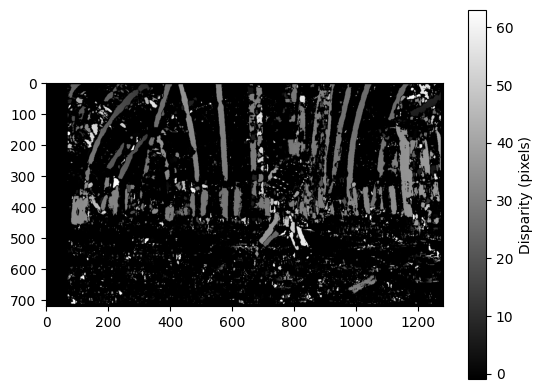

In [3]:
import cv2
import matplotlib.pyplot as plt

left = cv2.imread("/Users/nicolai/Documents/Masters_1_semester/34759 Perception for autonomous systems, Fall 2026/perception-course/0_calib/left/000.png", cv2.IMREAD_GRAYSCALE)
right = cv2.imread("/Users/nicolai/Documents/Masters_1_semester/34759 Perception for autonomous systems, Fall 2026/perception-course/0_calib/right/000.png", cv2.IMREAD_GRAYSCALE)

stereo = cv2.StereoBM_create(
    numDisparities=64,  # Disparity search range; must be a multiple of 16
    blockSize=15       # Matching window size; odd number, at least 5
)

disparity = stereo.compute(left, right).astype("float32") / 16.0

plt.imshow(disparity, cmap="gray")
plt.colorbar(label="Disparity (pixels)")
plt.show()

### 3d point cloud 

In [6]:
import numpy as np
import open3d as o3d
import cv2

points_3d = cv2.reprojectImageTo3D(disparity, Q)

rgb = cv2.cvtColor(left, cv2.COLOR_BGR2RGB)

mask = (
    (disparity > 1)
    & np.isfinite(points_3d).all(axis=2)
    & (points_3d[:, :, 2] > 0)
    & (points_3d[:, :, 2] < 5000)
)

points = points_3d[mask]
colors = rgb[mask].astype(np.float64) / 255.0

# Optional: reduce the number of points for smoother interaction
max_points = 100_000
if len(points) > max_points:
    indices = np.random.default_rng(0).choice(
        len(points), max_points, replace=False
    )
    points = points[indices]
    colors = colors[indices]

pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points)
pcd.colors = o3d.utility.Vector3dVector(colors)

# Optional cleanup/downsampling
pcd = pcd.voxel_down_sample(voxel_size=2.0)

o3d.visualization.draw_geometries(
    [pcd],
    window_name="Stereo 3D Point Cloud",
    width=1200,
    height=800,
    left=50,
    top=50,
)

In [7]:
ys, xs = np.where(mask)

points = points_3d[mask]
colors = rgb[mask].astype(np.float64) / 255.0

# Downsample consistently
max_points = 100_000
if len(points) > max_points:
    indices = np.random.default_rng(0).choice(
        len(points), max_points, replace=False
    )
    points = points[indices]
    colors = colors[indices]
    xs = xs[indices]
    ys = ys[indices]

pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points)
pcd.colors = o3d.utility.Vector3dVector(colors)

o3d.visualization.draw_geometries([pcd])